# Caderno de Estudo e Simulação: Camada Densa (Forward e Backward)

> **Objetivo:** Este caderno serve como ambiente interativo e visual para dissecar a transformação afim da camada densa ($Z = XW + b$), a intuição geométrica da distorção espacial dos dados, a dedução das derivadas matriciais no *backpropagation* e a validação numérica por diferenças finitas.
>
> **Nota de uso:** Destinado ao estudo aprofundado e preparação para a arguição oral da disciplina de Aprendizado de Máquinas (INE5664 - UFSC).


In [1]:
import sys
from pathlib import Path

# Garante que a raiz do projeto esteja no sys.path
raiz_projeto = Path.cwd().resolve()
while raiz_projeto.name != "projeto-final-mlp" and raiz_projeto.parent != raiz_projeto:
    raiz_projeto = raiz_projeto.parent
if str(raiz_projeto) not in sys.path:
    sys.path.insert(0, str(raiz_projeto))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# Estilização visual dos gráficos
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
plt.rcParams["figure.dpi"] = 120

from mlp.camadas import Densa
from mlp.inicializadores import GlorotUniforme, Zeros
from mlp.custos import MSE

print("Ambiente configurado com sucesso!")
print(f"NumPy versão: {np.__version__}")
print(f"Raiz do projeto: {raiz_projeto}")


Ambiente configurado com sucesso!
NumPy versão: 1.26.4
Raiz do projeto: /home/luizeduardo/_dev/faculdade/aprendizado_maquinas/projeto-final-mlp


## 1. Intuição Geométrica: A Camada Densa como Transformação Afim

A camada densa sem função de ativação realiza uma **transformação afim** no espaço euclidiano:

$$Z = X W + b$$

Essa operação pode ser decomposta em dois movimentos fundamentais:
1. **Transformação Linear ($X W$):** a matriz de pesos $W$ estica, comprime, reflete e rotaciona o espaço. No entanto, ela **mantém a origem fixa** em $(0, 0)$.
2. **Translação ($+ b$):** o vetor de viés (*bias*) desloca todo o espaço transformado, movendo a origem para uma nova posição.

### Por que o viés $b$ é indispensável?
Sem o viés ($b = 0$), qualquer hiperplano de separação gerado pela camada seria forçado a passar pelo ponto $(0, 0, \dots, 0)$. Isso tornaria impossível separar classes ou ajustar funções lineares onde a fronteira ideal esteja deslocada da origem.

Abaixo, simulamos uma grade regular 2D de pontos e observamos sua deformação através da camada densa.


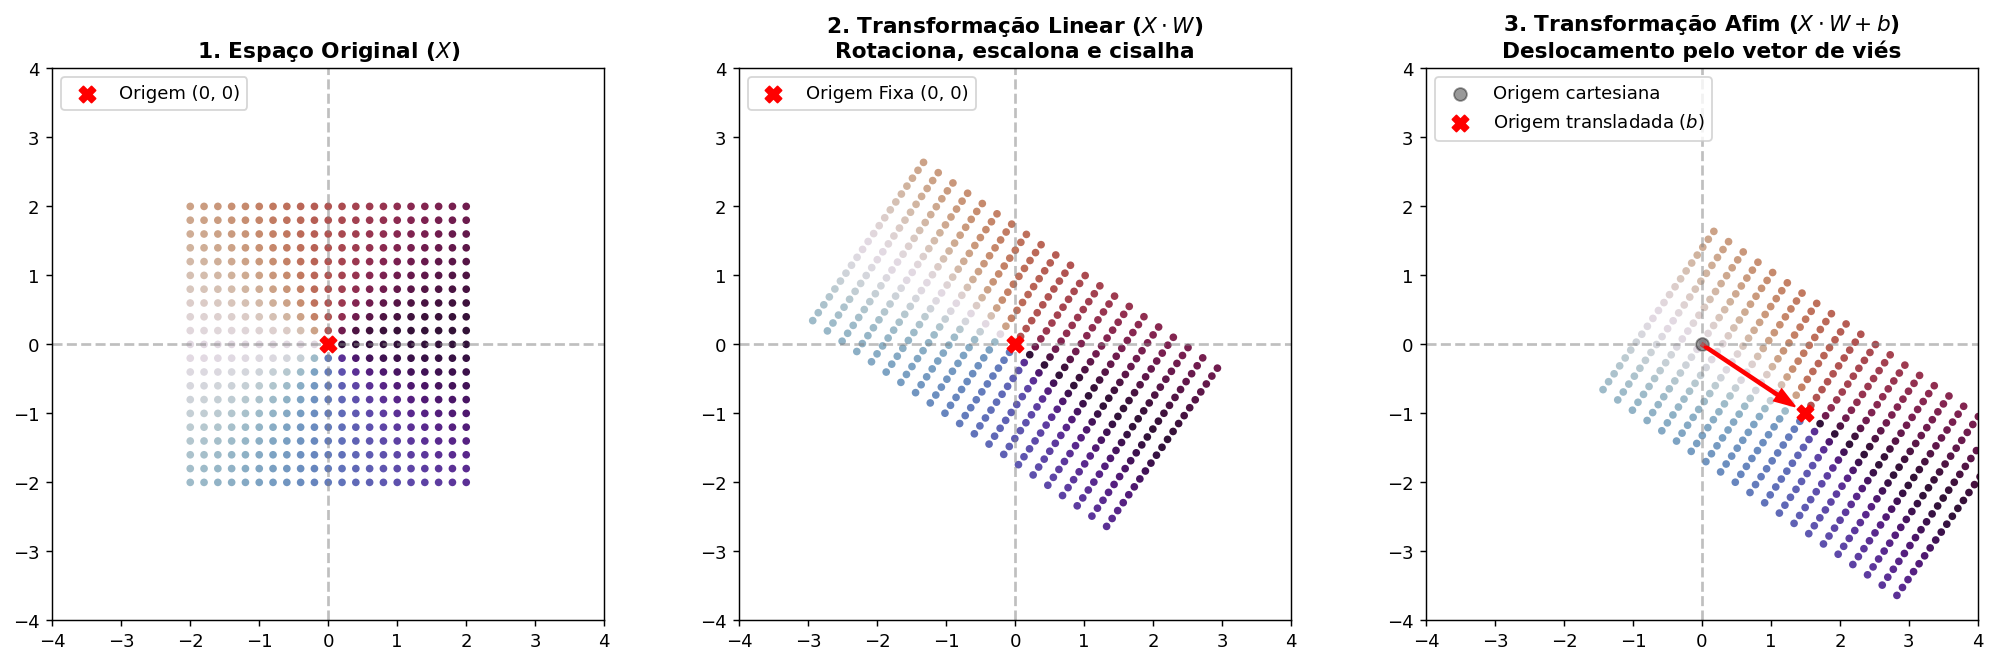

In [2]:
# Criação de uma grade cartesiana 2D [-2, 2] x [-2, 2]
n_pontos_eixo = 21
x1_lin = np.linspace(-2.0, 2.0, n_pontos_eixo)
x2_lin = np.linspace(-2.0, 2.0, n_pontos_eixo)
X1, X2 = np.meshgrid(x1_lin, x2_lin)
grid_pontos = np.column_stack([X1.ravel(), X2.ravel()])  # Formato (N, 2)

# Mapeamento de cores baseado nas coordenadas originais para rastrear deformações
cores = np.arctan2(grid_pontos[:, 1], grid_pontos[:, 0])

# Configuração de uma Camada Densa com transformação linear conhecida:
# Rotação de ~30 graus + cisalhamento e escalonamento
theta = np.radians(35)
escala_x, escala_y = 1.3, 0.7
W_custom = np.array([
    [escala_x * np.cos(theta), -escala_x * np.sin(theta)],
    [escala_y * np.sin(theta),  escala_y * np.cos(theta)]
])
b_custom = np.array([[1.5, -1.0]])  # Translação não nula

# Aplicação das transformações passo a passo
apenas_linear = grid_pontos @ W_custom
afim_completo = grid_pontos @ W_custom + b_custom

# Visualização gráfica comparativa
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Espaço Original
sc1 = axes[0].scatter(grid_pontos[:, 0], grid_pontos[:, 1], c=cores, cmap="twilight", s=18, edgecolors="none")
axes[0].axhline(0, color="gray", linestyle="--", alpha=0.5)
axes[0].axvline(0, color="gray", linestyle="--", alpha=0.5)
axes[0].scatter([0], [0], color="red", s=80, marker="X", zorder=5, label="Origem (0, 0)")
axes[0].set_title("1. Espaço Original ($X$)", fontweight="bold")
axes[0].set_xlim(-4, 4)
axes[0].set_ylim(-4, 4)
axes[0].set_aspect("equal")
axes[0].legend(loc="upper left")

# 2. Transformação Linear (X * W)
axes[1].scatter(apenas_linear[:, 0], apenas_linear[:, 1], c=cores, cmap="twilight", s=18, edgecolors="none")
axes[1].axhline(0, color="gray", linestyle="--", alpha=0.5)
axes[1].axvline(0, color="gray", linestyle="--", alpha=0.5)
axes[1].scatter([0], [0], color="red", s=80, marker="X", zorder=5, label="Origem Fixa (0, 0)")
axes[1].set_title("2. Transformação Linear ($X \cdot W$)\nRotaciona, escalona e cisalha", fontweight="bold")
axes[1].set_xlim(-4, 4)
axes[1].set_ylim(-4, 4)
axes[1].set_aspect("equal")
axes[1].legend(loc="upper left")

# 3. Transformação Afim Completa (X * W + b)
axes[2].scatter(afim_completo[:, 0], afim_completo[:, 1], c=cores, cmap="twilight", s=18, edgecolors="none")
axes[2].axhline(0, color="gray", linestyle="--", alpha=0.5)
axes[2].axvline(0, color="gray", linestyle="--", alpha=0.5)
axes[2].scatter([0], [0], color="black", s=50, marker="o", alpha=0.4, label="Origem cartesiana")
axes[2].scatter([b_custom[0, 0]], [b_custom[0, 1]], color="red", s=80, marker="X", zorder=5, label="Origem transladada ($b$)")
axes[2].arrow(0, 0, b_custom[0, 0] * 0.9, b_custom[0, 1] * 0.9, color="red", width=0.04, head_width=0.2, length_includes_head=True)
axes[2].set_title("3. Transformação Afim ($X \cdot W + b$)\nDeslocamento pelo vetor de viés", fontweight="bold")
axes[2].set_xlim(-4, 4)
axes[2].set_ylim(-4, 4)
axes[2].set_aspect("equal")
axes[2].legend(loc="upper left")

plt.tight_layout()
plt.show()


## 2. Rastreamento Dimensional e Fluxo Matricial no Passo à Frente

No Perceptron Multicamadas, os dados transitam em **mini-lotes** (*mini-batches*) de $N$ amostras simultâneas.

### Dimensões dos Tensores:
- **Matriz de Entrada ($X$):** $(N, d_{\text{in}})$ — $N$ amostras, cada uma com $d_{\text{in}}$ características (*features*).
- **Matriz de Pesos ($W$):** $(d_{\text{in}}, d_{\text{out}})$ — sinapses conectando cada entrada a cada neurônio de saída.
- **Vetor de Vieses ($b$):** $(1, d_{\text{out}})$ — termo independente de cada neurônio de saída.
- **Matriz de Saída Linear ($Z$):** $(N, d_{\text{out}})$ — pré-ativações calculadas.

$$\underbrace{Z}_{(N \times d_{\text{out}})} = \underbrace{X}_{(N \times d_{\text{in}})} \cdot \underbrace{W}_{(d_{\text{in}} \times d_{\text{out}})} + \underbrace{b}_{(1 \times d_{\text{out}})}$$

### Por que a camada faz cache de $X$?
No método `passo_a_frente`, a classe `Densa` executa `self.entradas = entradas`. Esse armazenamento em cache é essencial porque a derivada $\dfrac{\partial L}{\partial W} = X^T \cdot \delta$ requer diretamente os valores de $X$. Sem esse cache, seria necessário recomputar todo o caminho de ida durante a retropropagação.


In [3]:
# Demonstração prática do Passo à Frente
rng = np.random.RandomState(42)

dim_in = 3
dim_out = 2
batch_size = 4

# Instanciação da Camada Densa com inicializador Glorot Uniforme
camada = Densa(dimensao_entrada=dim_in, dimensao_saida=dim_out, gerador_aleatorio=rng)

# Criação de um lote de teste sintético
X_batch = rng.randn(batch_size, dim_in)

print("--- FORWARD PASS: DIMENSÕES E VALORES ---")
print(f"X (Entrada) formato: {X_batch.shape}")
print(f"W (Pesos) formato:   {camada.pesos.shape}")
print(f"b (Vieses) formato:  {camada.vieses.shape}")

# Execução do passo à frente
Z_batch = camada.passo_a_frente(X_batch)

print(f"Z (Saída linear) formato: {Z_batch.shape}")
print("\nVerificação explícita: Z[0] calculado pelo método vs cálculo manual:")
Z_manual_0 = X_batch[0:1] @ camada.pesos + camada.vieses
print(f"Z método[0]: {Z_batch[0]}")
print(f"Z manual[0]: {Z_manual_0[0]}")
print(f"Diferença máxima: {np.max(np.abs(Z_batch[0] - Z_manual_0[0])):.2e}")
print(f"Cache de entradas ativo: {camada.entradas is not None} com formato {camada.entradas.shape}")


--- FORWARD PASS: DIMENSÕES E VALORES ---
X (Entrada) formato: (4, 3)
W (Pesos) formato:   (3, 2)
b (Vieses) formato:  (1, 2)
Z (Saída linear) formato: (4, 2)

Verificação explícita: Z[0] calculado pelo método vs cálculo manual:
Z método[0]: [0.309798   2.07913186]
Z manual[0]: [0.309798   2.07913186]
Diferença máxima: 0.00e+00
Cache de entradas ativo: True com formato (4, 3)


## 3. A Mecânica do Backward Pass: Regra da Cadeia Tensorial

Durante a retropropagação, a camada densa recebe o gradiente da função de custo $L$ em relação à sua saída linear $Z$:

$$\delta = \frac{\partial L}{\partial Z} \in \mathbb{R}^{N \times d_{\text{out}}}$$

A partir de $\delta$ e das entradas armazenadas em cache $X$, a camada calcula três gradientes analíticos fundamentais:

### 1. Gradiente dos Pesos ($\partial L / \partial W$)
$$\frac{\partial L}{\partial W} = X^T \cdot \delta$$
- **Formato:** $(d_{\text{in}} \times N) \times (N \times d_{\text{out}}) = (d_{\text{in}} \times d_{\text{out}})$
- **Intuição:** a multiplicação por $X^T$ acumula a correlação entre as entradas $X$ e os erros $\delta$ somando sobre todas as $N$ amostras do lote.

### 2. Gradiente do Viés ($\partial L / \partial b$)
$$\frac{\partial L}{\partial b} = \sum_{i=1}^N \delta_{i, :}$$
- **Formato:** $(1 \times d_{\text{out}})$
- **Intuição:** como a derivada de $Z_{ij}$ em relação a $b_j$ é 1, o gradiente do viés é simplesmente a soma dos gradientes de saída de todas as amostras para cada neurônio.

### 3. Gradiente da Entrada ($\partial L / \partial X$)
$$\frac{\partial L}{\partial X} = \delta \cdot W^T$$
- **Formato:** $(N \times d_{\text{out}}) \times (d_{\text{out}} \times d_{\text{in}}) = (N \times d_{\text{in}})$
- **Intuição:** projeta o erro $\delta$ de volta para o espaço de entrada através dos pesos transpostos $W^T$, permitindo que camadas anteriores continuem a retropropagação.


--- BACKWARD PASS: DIMENSÕES CALCULADAS ---
Gradiente recebido (dL/dZ): (4, 2)
Gradiente dos Pesos (dW):    (3, 2) (esperado: 3 x 2)
Gradiente do Viés (db):     (1, 2) (esperado: 1 x 2)
Gradiente da Entrada (dX):  (4, 3) (esperado: 4 x 3)


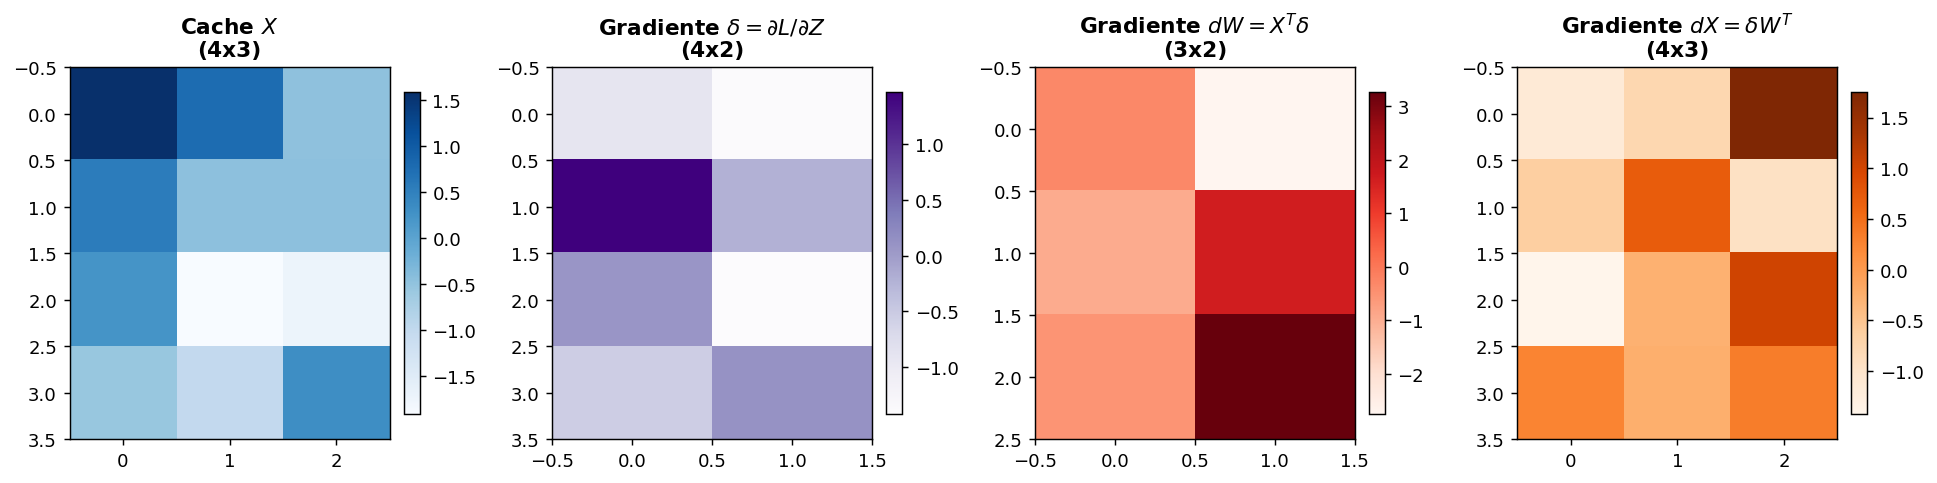

In [4]:
# Demonstração prática do Passo Atrás com visualização matricial
delta_saida = rng.randn(batch_size, dim_out)  # dL/dZ sintético recebido da próxima camada

# Execução do backward
dX = camada.passo_atras(delta_saida)
dW = camada.gradiente_pesos
db = camada.gradiente_vieses

print("--- BACKWARD PASS: DIMENSÕES CALCULADAS ---")
print(f"Gradiente recebido (dL/dZ): {delta_saida.shape}")
print(f"Gradiente dos Pesos (dW):    {dW.shape} (esperado: {dim_in} x {dim_out})")
print(f"Gradiente do Viés (db):     {db.shape} (esperado: 1 x {dim_out})")
print(f"Gradiente da Entrada (dX):  {dX.shape} (esperado: {batch_size} x {dim_in})")

# Visualização de calor (Heatmaps) dos tensores no Forward e Backward
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))

im0 = axes[0].imshow(X_batch, cmap="Blues", aspect="auto")
axes[0].set_title(f"Cache $X$\n({X_batch.shape[0]}x{X_batch.shape[1]})", fontweight="bold")
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(delta_saida, cmap="Purples", aspect="auto")
axes[1].set_title(f"Gradiente $\delta = \partial L / \partial Z$\n({delta_saida.shape[0]}x{delta_saida.shape[1]})", fontweight="bold")
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(dW, cmap="Reds", aspect="auto")
axes[2].set_title(f"Gradiente $dW = X^T \delta$\n({dW.shape[0]}x{dW.shape[1]})", fontweight="bold")
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

im3 = axes[3].imshow(dX, cmap="Oranges", aspect="auto")
axes[3].set_title(f"Gradiente $dX = \delta W^T$\n({dX.shape[0]}x{dX.shape[1]})", fontweight="bold")
plt.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


## 4. Validação Rigorosa: Verificação Numérica de Gradientes (Gradient Checking)

Para garantir que as derivadas analíticas implementadas em `passo_atras` estejam matematicamente perfeitas, utilizamos a **aproximação numérica por diferenças finitas centradas**:

$$\frac{\partial L}{\partial \theta} \approx \frac{L(\theta + \epsilon) - L(\theta - \epsilon)}{2\epsilon}$$

Onde $\epsilon$ é uma perturbação infinitesimal (usualmente $10^{-7}$).

O **erro relativo** entre o gradiente analítico ($g_a$) e o numérico ($g_n$) é definido por:

$$\text{Erro Relativo} = \frac{\|g_a - g_n\|_2}{\|g_a\|_2 + \|g_n\|_2 + 10^{-12}}$$

### Critérios de Aceitação da Literatura (ex.: Stanford CS231n):
- $\text{Erro Relativo} \le 10^{-7}$: **Excelente.** Confirmação analítica exata da derivada.
- $10^{-7} < \text{Erro Relativo} \le 10^{-4}$: **Aceitável**, com possível ruído numérico de ponto flutuante.
- $\text{Erro Relativo} > 10^{-2}$: **Erro de implementação.** Derivada analítica incorreta.

Abaixo, testamos rigorosamente os gradientes em relação a $W$, $b$ e $X$.


--- RELATÓRIO DE VERIFICAÇÃO NUMÉRICA ---
Erro Relativo em W: 4.68e-10 -> PERFEITO (< 1e-7)
Erro Relativo em b: 1.33e-08 -> PERFEITO (< 1e-7)
Erro Relativo em X: 7.86e-10 -> PERFEITO (< 1e-7)


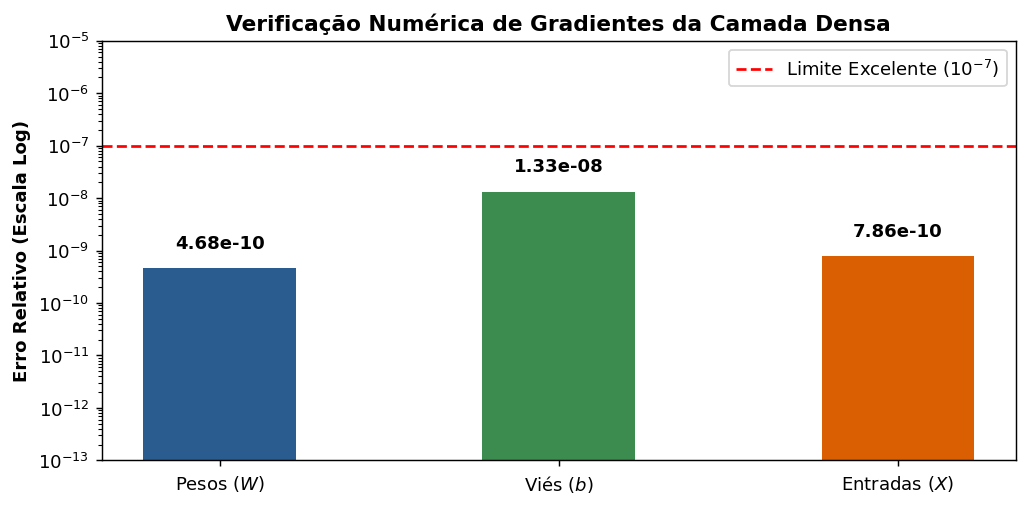

In [5]:
# Função objetivo escalar: L = 0.5 * sum(Z^2)
def calcular_custo_escalar(X_in, W_in, b_in):
    Z = X_in @ W_in + b_in
    return 0.5 * np.sum(Z ** 2)

# Gradiente analítico da perda escalar:
# dL/dZ = Z
Z_analitico = camada.passo_a_frente(X_batch)
delta_loss = Z_analitico  # dL/dZ
dX_analitico = camada.passo_atras(delta_loss)
dW_analitico = camada.gradiente_pesos
db_analitico = camada.gradiente_vieses

epsilon = 1e-7

# 1. Gradiente Numérico para W
dW_num = np.zeros_like(camada.pesos)
for i in range(camada.pesos.shape[0]):
    for j in range(camada.pesos.shape[1]):
        W_plus = camada.pesos.copy()
        W_minus = camada.pesos.copy()
        W_plus[i, j] += epsilon
        W_minus[i, j] -= epsilon
        cost_plus = calcular_custo_escalar(X_batch, W_plus, camada.vieses)
        cost_minus = calcular_custo_escalar(X_batch, W_minus, camada.vieses)
        dW_num[i, j] = (cost_plus - cost_minus) / (2 * epsilon)

# 2. Gradiente Numérico para b
db_num = np.zeros_like(camada.vieses)
for j in range(camada.vieses.shape[1]):
    b_plus = camada.vieses.copy()
    b_minus = camada.vieses.copy()
    b_plus[0, j] += epsilon
    b_minus[0, j] -= epsilon
    cost_plus = calcular_custo_escalar(X_batch, camada.pesos, b_plus)
    cost_minus = calcular_custo_escalar(X_batch, camada.pesos, b_minus)
    db_num[0, j] = (cost_plus - cost_minus) / (2 * epsilon)

# 3. Gradiente Numérico para X
dX_num = np.zeros_like(X_batch)
for i in range(X_batch.shape[0]):
    for k in range(X_batch.shape[1]):
        X_plus = X_batch.copy()
        X_minus = X_batch.copy()
        X_plus[i, k] += epsilon
        X_minus[i, k] -= epsilon
        cost_plus = calcular_custo_escalar(X_plus, camada.pesos, camada.vieses)
        cost_minus = calcular_custo_escalar(X_minus, camada.pesos, camada.vieses)
        dX_num[i, k] = (cost_plus - cost_minus) / (2 * epsilon)

def erro_relativo(ga, gn):
    norm_diff = np.linalg.norm(ga - gn)
    norm_sum = np.linalg.norm(ga) + np.linalg.norm(gn)
    return norm_diff / max(norm_sum, 1e-12)

err_W = erro_relativo(dW_analitico, dW_num)
err_b = erro_relativo(db_analitico, db_num)
err_X = erro_relativo(dX_analitico, dX_num)

print("--- RELATÓRIO DE VERIFICAÇÃO NUMÉRICA ---")
print(f"Erro Relativo em W: {err_W:.2e} -> {'PERFEITO (< 1e-7)' if err_W < 1e-7 else 'VERIFICAR'}")
print(f"Erro Relativo em b: {err_b:.2e} -> {'PERFEITO (< 1e-7)' if err_b < 1e-7 else 'VERIFICAR'}")
print(f"Erro Relativo em X: {err_X:.2e} -> {'PERFEITO (< 1e-7)' if err_X < 1e-7 else 'VERIFICAR'}")

# Gráfico de barras comparando a precisão
fig, ax = plt.subplots(figsize=(8, 4))
variaveis = ["Pesos ($W$)", "Viés ($b$)", "Entradas ($X$)"]
erros = [err_W, err_b, err_X]
barras = ax.bar(variaveis, erros, color=["#2b5c8f", "#3c8b4f", "#d95f02"], width=0.45)
ax.axhline(1e-7, color="red", linestyle="--", linewidth=1.5, label="Limite Excelente ($10^{-7}$)")
ax.set_yscale("log")
ax.set_ylabel("Erro Relativo (Escala Log)", fontweight="bold")
ax.set_title("Verificação Numérica de Gradientes da Camada Densa", fontweight="bold")
ax.set_ylim(1e-13, 1e-5)
ax.legend(loc="upper right")

for b, err in zip(barras, erros):
    ax.annotate(f"{err:.2e}", (b.get_x() + b.get_width() / 2, err * 2),
                ha="center", va="bottom", fontweight="bold", fontsize=10)

plt.tight_layout()
plt.show()


## 5. Simulação de Otimização: Ajuste de Parâmetros com SGD

O método `atualizar_parametros(taxa_aprendizado)` aplica o passo da descida do gradiente estocástico:

$$W \leftarrow W - \eta \cdot \frac{\partial L}{\partial W}$$
$$b \leftarrow b - \eta \cdot \frac{\partial L}{\partial b}$$

Abaixo, simulamos uma camada densa $2 \to 1$ aprendendo a identificar uma relação linear real:

$$y = 2.0 \cdot x_1 - 1.5 \cdot x_2 + 0.8$$

Acompanhamos a queda da função de custo MSE e a convergência dos parâmetros estimados em direção aos valores reais.


Custo Inicial: 13.6492 -> Custo Final: 2.1152e-03
Valores reais:     w1=2.00, w2=-1.50, b=0.80
Valores aprendidos: w1=2.01, w2=-1.50, b=0.79


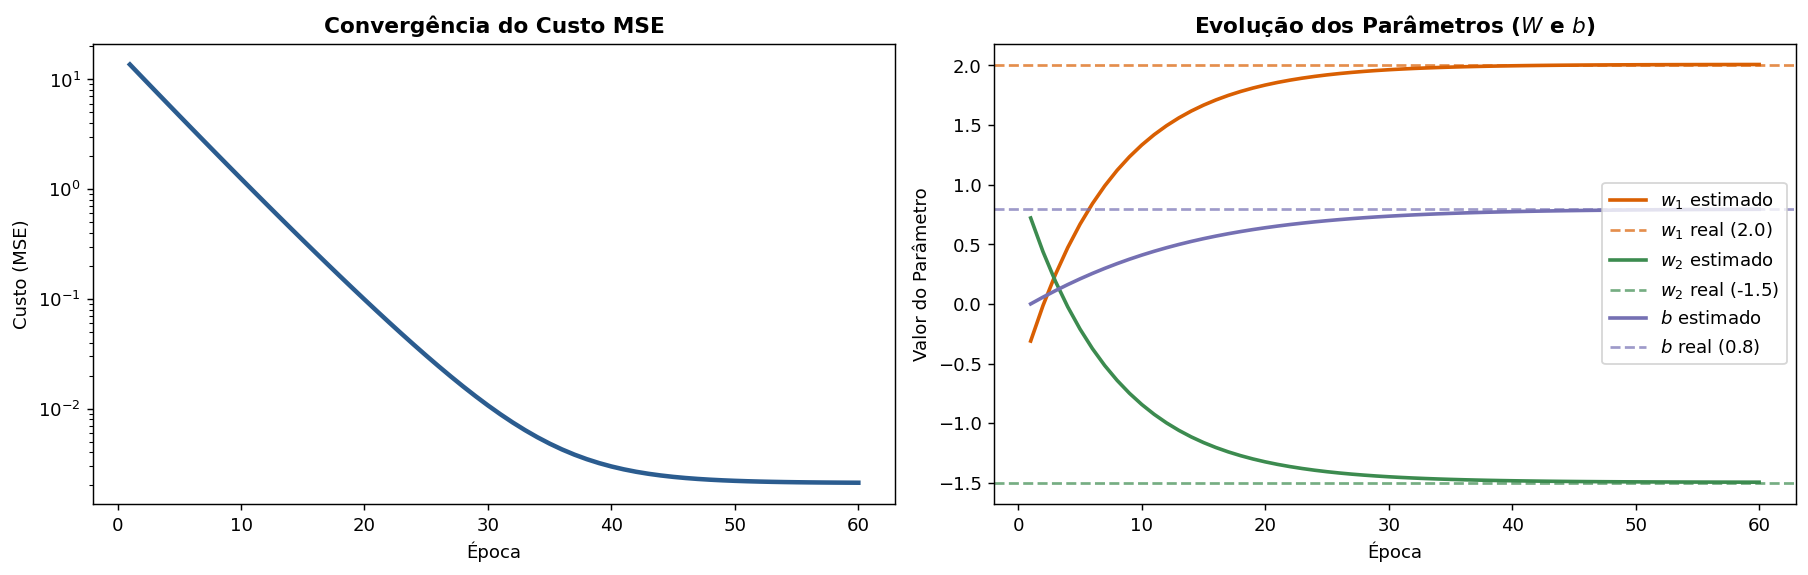

In [6]:
# Geração de conjunto de dados sintético
rng_opt = np.random.RandomState(123)
N_amostras = 100
X_treino = rng_opt.uniform(-2, 2, size=(N_amostras, 2))

# Relação alvo real
W_real = np.array([[2.0], [-1.5]])
b_real = np.array([[0.8]])
y_real = X_treino @ W_real + b_real + rng_opt.normal(0, 0.05, size=(N_amostras, 1))

# Inicialização da Camada Densa e Custo MSE
camada_linear = Densa(dimensao_entrada=2, dimensao_saida=1, gerador_aleatorio=rng_opt)
funcao_custo = MSE()

taxa_aprendizado = 0.05
epocas = 60
historico_custo = []
historico_W = []
historico_b = []

# Loop de treinamento por gradiente descendente
for epoca in range(epocas):
    # 1. Forward
    y_pred = camada_linear.passo_a_frente(X_treino)
    custo = funcao_custo.calcular_custo(y_real, y_pred)
    historico_custo.append(custo)
    historico_W.append(camada_linear.pesos.flatten().copy())
    historico_b.append(camada_linear.vieses[0, 0].copy())
    
    # 2. Backward
    grad_custo = funcao_custo.gradiente(y_real, y_pred)
    camada_linear.passo_atras(grad_custo)
    
    # 3. Atualização de parâmetros
    camada_linear.atualizar_parametros(taxa_aprendizado)

historico_W = np.array(historico_W)
historico_b = np.array(historico_b)

# Visualização gráfica do aprendizado
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Curva de Custo MSE
axes[0].plot(range(1, epocas + 1), historico_custo, color="#2b5c8f", linewidth=2.5)
axes[0].set_title("Convergência do Custo MSE", fontweight="bold")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Custo (MSE)")
axes[0].set_yscale("log")

# Trajetória dos Parâmetros Estimados vs Reais
axes[1].plot(range(1, epocas + 1), historico_W[:, 0], label="$w_1$ estimado", color="#d95f02", linewidth=2)
axes[1].axhline(W_real[0, 0], color="#d95f02", linestyle="--", alpha=0.7, label="$w_1$ real (2.0)")

axes[1].plot(range(1, epocas + 1), historico_W[:, 1], label="$w_2$ estimado", color="#3c8b4f", linewidth=2)
axes[1].axhline(W_real[1, 0], color="#3c8b4f", linestyle="--", alpha=0.7, label="$w_2$ real (-1.5)")

axes[1].plot(range(1, epocas + 1), historico_b, label="$b$ estimado", color="#7570b3", linewidth=2)
axes[1].axhline(b_real[0, 0], color="#7570b3", linestyle="--", alpha=0.7, label="$b$ real (0.8)")

axes[1].set_title("Evolução dos Parâmetros ($W$ e $b$)", fontweight="bold")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Valor do Parâmetro")
axes[1].legend(loc="center right")

plt.tight_layout()
plt.show()

print(f"Custo Inicial: {historico_custo[0]:.4f} -> Custo Final: {historico_custo[-1]:.4e}")
print(f"Valores reais:     w1={W_real[0,0]:.2f}, w2={W_real[1,0]:.2f}, b={b_real[0,0]:.2f}")
print(f"Valores aprendidos: w1={camada_linear.pesos[0,0]:.2f}, w2={camada_linear.pesos[1,0]:.2f}, b={camada_linear.vieses[0,0]:.2f}")


## 6. Guia Prático para a Arguição Oral com o Professor

### P1: Qual é a função matemática exata da camada densa no MLP?
**Resposta:** É uma transformação afim dada por $Z = XW + b$. A matriz de pesos $W$ efetua rotação, cisalhamento e escalonamento dos eixos coordenados, enquanto o vetor de viés $b$ desloca a origem dos eixos.

### P2: Por que fazemos cache de $X$ no método `passo_a_frente`?
**Resposta:** Porque a derivada em relação aos pesos é $\dfrac{\partial L}{\partial W} = X^T \cdot \delta$. Como essa equação depende expressamente dos valores de entrada da camada, precisamos manter $X$ armazenado até a execução do `passo_atras`.

### P3: Por que no cálculo de $\dfrac{\partial L}{\partial b}$ somamos no eixo das amostras (`axis=0`)?
**Resposta:** Porque durante o passo à frente, o mesmo vetor de viés $b \in \mathbb{R}^{1 \times d_{\text{out}}}$ foi somado (por *broadcasting*) a todas as $N$ amostras do mini-lote. Pela regra da cadeia multivariada, a derivada total de uma variável que contribui para múltiplos caminhos é a soma das derivadas em cada um desses caminhos: $\dfrac{\partial L}{\partial b} = \sum_{i=1}^N \delta_{i, :}$.

### P4: Por que transpomos $X$ e $W$ nas multiplicações matriciais do backward?
**Resposta:** Para satisfazer o produto de matrizes e realizar a contração correta dos índices. Para os pesos, multiplicamos $(d_{\text{in}} \times N) \times (N \times d_{\text{out}}) = d_{\text{in}} \times d_{\text{out}}$, acumulando a soma sobre as $N$ amostras. Para a entrada, multiplicamos $(N \times d_{\text{out}}) \times (d_{\text{out}} \times d_{\text{in}}) = N \times d_{\text{in}}$, acumulando a contribuição de todos os $d_{\text{out}}$ neurônios da camada.

### P5: O que aconteceria se inicializássemos todos os pesos $W$ com zeros?
**Resposta:** Ocorreriam duas falhas críticas:
1. Todos os neurônios da camada produziriam exatamente a mesma saída linear ($Z_{i, 1} = Z_{i, 2} = \dots = b_j$).
2. No backward, todos os neurônios receberiam exatamente o mesmo gradiente, sofrendo idêntica atualização de pesos. A rede perderia a **capacidade de quebrar a simetria**, comportando-se efetivamente como se possuísse apenas um único neurônio por camada.
